# Exploratory Analysis and Interactive Visualisation of Morocco Electricity Consumption

**AnalystLab Africa · Experience Lab Internship · Week 5 · Data Analytics track**
**Author:** Ada Eudoxie

An energy management organisation in Morocco records electricity consumption for three distribution zones every 10 minutes, together with weather readings. In this notebook I explore one year of these readings (1 January to 30 December 2017) to understand when consumption peaks, how the three zones differ, and how consumption moves with temperature, humidity and wind speed.

**Business questions**

1. What patterns can be identified in electricity consumption across the three zones?
2. During which hours and days does consumption tend to be highest and lowest?
3. How does consumption vary across the months of the year?
4. Are temperature, humidity and wind speed associated with consumption?
5. Which zone records the highest and lowest consumption?
6. How can historical consumption patterns support better energy planning and management?

**Notebook outline**

1. Dataset understanding and inspection
2. Data cleaning and preparation
3. Electricity consumption analysis
4. Environmental relationship analysis
5. Interactive visualisation (Plotly)
6. Business insights and recommendations

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
IMG_DIR = ROOT / "images"
REPORT_DIR = ROOT / "reports"
IMG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pio.renderers.default = "notebook_connected"

ZONES = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
ZONE_LABELS = {"PowerConsumption_Zone1": "Zone 1", "PowerConsumption_Zone2": "Zone 2", "PowerConsumption_Zone3": "Zone 3"}
ZONE_COLORS = {"Zone 1": "#2a78d6", "Zone 2": "#eb6834", "Zone 3": "#1baf7a"}
ENV = ["Temperature", "Humidity", "WindSpeed"]
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "legend.frameon": False,
})
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f2f1ec", "#eb6834"])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
kw_fmt = mtick.FuncFormatter(lambda x, _: f"{x/1000:,.0f}k")

## 1. Dataset Understanding and Inspection

### 1.1 Load the data

In [2]:
raw = pd.read_csv(DATA_DIR / "powerconsumption.csv")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 52,416 | Columns: 9


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96"
1,1/1/2017 0:10,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08"
2,1/1/2017 0:20,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43"
3,1/1/2017 0:30,6.12,75.00,0.08,0.09,0.10,"28,228.86","18,361.09","18,899.28"
4,1/1/2017 0:40,5.92,75.70,0.08,0.05,0.09,"27,335.70","17,872.34","18,442.41"


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature,"52,416.00",18.81,5.82,3.25,14.41,18.78,22.89,40.01
Humidity,"52,416.00",68.26,15.55,11.34,58.31,69.86,81.40,94.80
WindSpeed,"52,416.00",1.96,2.35,0.05,0.08,0.09,4.92,6.48
GeneralDiffuseFlows,"52,416.00",182.70,264.40,0.00,0.06,5.04,319.60,"1,163.00"
DiffuseFlows,"52,416.00",75.03,124.21,0.01,0.12,4.46,101.00,936.00
PowerConsumption_Zone1,"52,416.00","32,344.97","7,130.56","13,895.70","26,310.67","32,265.92","37,309.02","52,204.40"
PowerConsumption_Zone2,"52,416.00","21,042.51","5,201.47","8,560.08","16,980.77","20,823.17","24,713.72","37,408.86"
PowerConsumption_Zone3,"52,416.00","17,835.41","6,622.17","5,935.17","13,129.33","16,415.12","21,624.10","47,598.33"


### 1.2 Data dictionary and interpretation notes

The supplied data dictionary gives a one-line description for each field. I load it below if it is in the `data/` folder, and then write down how I am interpreting each field, because two areas needed checking before any analysis.

In [5]:
dict_path = DATA_DIR / "powerconsumption_datadictionary.csv"
if dict_path.exists():
    display(pd.read_csv(dict_path))
else:
    print("Data dictionary file not found in data/. Field notes are documented below.")

Data dictionary file not found in data/. Field notes are documented below.


| Column | Description | How I treat it in this analysis |
|---|---|---|
| Datetime | Date and time of each observation | Parsed to datetime. One row every 10 minutes. |
| Temperature | Recorded temperature | Air temperature in °C (values range from about 3 to 40, which fits a Mediterranean climate). |
| Humidity | Recorded humidity | Relative humidity in %. |
| WindSpeed | Recorded wind speed | Unit not stated. The values are bimodal (see section 2.4), so I interpret this field with caution. |
| GeneralDiffuseFlows | General diffuse flow measurement | Physical meaning is not defined by the dictionary or the original source. The values are zero at night and rise during the day, so they behave like a solar radiation reading, but no unit is confirmed. I describe them but keep them out of the main conclusions. |
| DiffuseFlows | Diffuse flow measurement | Same as above. |
| PowerConsumption_Zone1/2/3 | Electricity consumption in each zone | Neither the dictionary nor the original source states a unit, and values sit between roughly 6,000 and 52,000. I treat each reading as the **average power demand (load) during that 10-minute interval** (most likely kW), not as energy used in the interval. |

**Why the consumption interpretation matters:** if each reading is a power level, adding up the 52,416 readings does not give total energy. Energy would be power multiplied by time (for kW readings, `reading × 10/60` gives kWh for the interval). Because the unit is not confirmed, I compare zones and time periods using **average demand** rather than totals throughout this notebook. Averages are valid whichever unit is correct, and they are also not affected by months having different numbers of days.

### 1.3 Missing values, duplicates and data types

In [6]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(),
})
quality

,dtype,missing,missing_%,unique_values
Datetime,str,0,0.00,52416
Temperature,float64,0,0.00,3437
Humidity,float64,0,0.00,4443
WindSpeed,float64,0,0.00,548
GeneralDiffuseFlows,float64,0,0.00,10504
DiffuseFlows,float64,0,0.00,10449
PowerConsumption_Zone1,float64,0,0.00,27709
PowerConsumption_Zone2,float64,0,0.00,29621
PowerConsumption_Zone3,float64,0,0.00,22838


In [7]:
print("Fully duplicated rows:", raw.duplicated().sum())
non_numeric = {c: pd.to_numeric(raw[c], errors="coerce").isna().sum() - raw[c].isna().sum() for c in raw.columns if c != "Datetime"}
print("Non-numeric entries in numeric columns:", non_numeric)

Fully duplicated rows: 0
Non-numeric entries in numeric columns: {'Temperature': np.int64(0), 'Humidity': np.int64(0), 'WindSpeed': np.int64(0), 'GeneralDiffuseFlows': np.int64(0), 'DiffuseFlows': np.int64(0), 'PowerConsumption_Zone1': np.int64(0), 'PowerConsumption_Zone2': np.int64(0), 'PowerConsumption_Zone3': np.int64(0)}


### 1.4 Datetime conversion and interval check

In [8]:
df = raw.copy()
df["Datetime"] = pd.to_datetime(df["Datetime"], format="mixed")

print("Unparsed timestamps:", df["Datetime"].isna().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())
print("First reading:", df["Datetime"].min())
print("Last reading: ", df["Datetime"].max())

expected = pd.date_range(df["Datetime"].min(), df["Datetime"].max(), freq="10min")
print(f"Expected 10-minute slots: {len(expected):,} | Rows in file: {len(df):,}")
print("Missing slots:", len(expected.difference(df["Datetime"])))

intervals = df.sort_values("Datetime")["Datetime"].diff().value_counts()
intervals

Unparsed timestamps: 0
Duplicate timestamps: 0
First reading: 2017-01-01 00:00:00
Last reading:  2017-12-30 23:50:00
Expected 10-minute slots: 52,416 | Rows in file: 52,416
Missing slots: 0


Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

In [9]:
print("Days covered:", df["Datetime"].dt.normalize().nunique())
print("Readings per day:", df.groupby(df["Datetime"].dt.date).size().value_counts().to_dict())

Days covered: 364
Readings per day: {144: 364}


### 1.5 Data quality log

| # | Check | Result | Action |
|---|---|---|---|
| 1 | Missing values | None in any column | No imputation needed. The cleaning step still includes interpolation for short gaps so the notebook works on an updated file. |
| 2 | Duplicate rows / timestamps | None | Kept the de-duplication step for reproducibility. |
| 3 | Datetime format | Stored as text (`m/d/yyyy h:mm`) | Converted to `datetime64`. |
| 4 | Interval consistency | Every gap is exactly 10 minutes; 144 readings on each of 364 days | No reindexing needed. |
| 5 | Coverage | 1 Jan 2017 00:00 to 30 Dec 2017 23:50. **31 December is not in the data.** | Monthly averages are used, so December is still comparable. |
| 6 | Units | Not stated for consumption, wind speed or diffuse flows | Consumption treated as average demand; comparisons use means, not sums. |
| 7 | Diffuse flow fields | Meaning not defined | Described but excluded from conclusions. |
| 8 | Wind speed | Bimodal, with readings clustered near 0.08 or near 4.9 | Flagged as a possible sensor or recording issue (section 2.4). |
| 9 | Zone 3 high values | Many IQR outliers | Investigated in section 2.3. They are a genuine summer pattern, not errors. |

## 2. Data Cleaning and Preparation

### 2.1 Cleaning steps

The data is already clean, but I wrote the steps so they would handle common issues if the file is refreshed: non-numeric entries, duplicate rows, duplicate timestamps and gaps in the 10-minute grid.

In [10]:
num_cols = [c for c in df.columns if c != "Datetime"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

df = (df.dropna(subset=["Datetime"])
        .drop_duplicates()
        .groupby("Datetime", as_index=True)[num_cols].mean()
        .sort_index())

full_index = pd.date_range(df.index.min(), df.index.max(), freq="10min", name="Datetime")
df = df.reindex(full_index)
gaps_before = df[num_cols].isna().sum().sum()

# Short gaps (up to 1 hour) are filled by time interpolation; longer gaps are left as missing
df[num_cols] = df[num_cols].interpolate(method="time", limit=6, limit_area="inside")
print(f"Missing cells before interpolation: {gaps_before} | after: {df[num_cols].isna().sum().sum()}")
print("Clean shape:", df.shape)

Missing cells before interpolation: 0 | after: 0
Clean shape: (52416, 8)


### 2.2 Time-based features

In [11]:
df["Year"] = df.index.year
df["Month"] = df.index.month
df["MonthName"] = pd.Categorical(df.index.strftime("%b"), categories=MONTH_ORDER, ordered=True)
df["Day"] = df.index.day
df["Hour"] = df.index.hour
df["DayOfWeek"] = pd.Categorical(df.index.day_name(), categories=DAY_ORDER, ordered=True)
df["Date"] = df.index.date
df["IsWeekend"] = df.index.dayofweek >= 5

df.head()

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,MonthName,Day,Hour,DayOfWeek,Date,IsWeekend
Datetime,,,,,,,,,,,,,,,,
2017-01-01 00:00:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96",2017,1,Jan,1,0,Sunday,2017-01-01,True
2017-01-01 00:10:00,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08",2017,1,Jan,1,0,Sunday,2017-01-01,True
2017-01-01 00:20:00,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43",2017,1,Jan,1,0,Sunday,2017-01-01,True
2017-01-01 00:30:00,6.12,75.00,0.08,0.09,0.10,"28,228.86","18,361.09","18,899.28",2017,1,Jan,1,0,Sunday,2017-01-01,True
2017-01-01 00:40:00,5.92,75.70,0.08,0.05,0.09,"27,335.70","17,872.34","18,442.41",2017,1,Jan,1,0,Sunday,2017-01-01,True


### 2.3 Unusual and extreme values

I used the 1.5 × IQR rule to flag unusual readings, then checked whether the flagged readings are errors or real behaviour.

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outliers = pd.DataFrame({
    "outliers": [iqr_outliers(df[c]) for c in ZONES + ENV],
    "min": [df[c].min() for c in ZONES + ENV],
    "max": [df[c].max() for c in ZONES + ENV],
}, index=ZONES + ENV)
outliers["outliers_%"] = (outliers["outliers"] / len(df) * 100).round(2)
outliers

,outliers,min,max,outliers_%
PowerConsumption_Zone1,0,"13,895.70","52,204.40",0.00
PowerConsumption_Zone2,7,"8,560.08","37,408.86",0.01
PowerConsumption_Zone3,1191,"5,935.17","47,598.33",2.27
Temperature,142,3.25,40.01,0.27
Humidity,291,11.34,94.80,0.56
WindSpeed,0,0.05,6.48,0.00


In [13]:
z3_q1, z3_q3 = df["PowerConsumption_Zone3"].quantile([0.25, 0.75])
z3_upper = z3_q3 + 1.5 * (z3_q3 - z3_q1)
z3_flags = df[df["PowerConsumption_Zone3"] > z3_upper]
print(f"Zone 3 upper fence: {z3_upper:,.0f}")
print("Flagged Zone 3 readings by month:")
print(z3_flags["MonthName"].value_counts().sort_index().loc[lambda s: s > 0])
print("\nFlagged Zone 3 readings by hour:")
print(z3_flags["Hour"].value_counts().sort_index().loc[lambda s: s > 0])

Zone 3 upper fence: 34,366
Flagged Zone 3 readings by month:
MonthName
Jul    760
Aug    431
Name: count, dtype: int64

Flagged Zone 3 readings by hour:
Hour
0      17
12      3
13      5
18      9
19    222
20    317
21    299
22    217
23    102
Name: count, dtype: int64


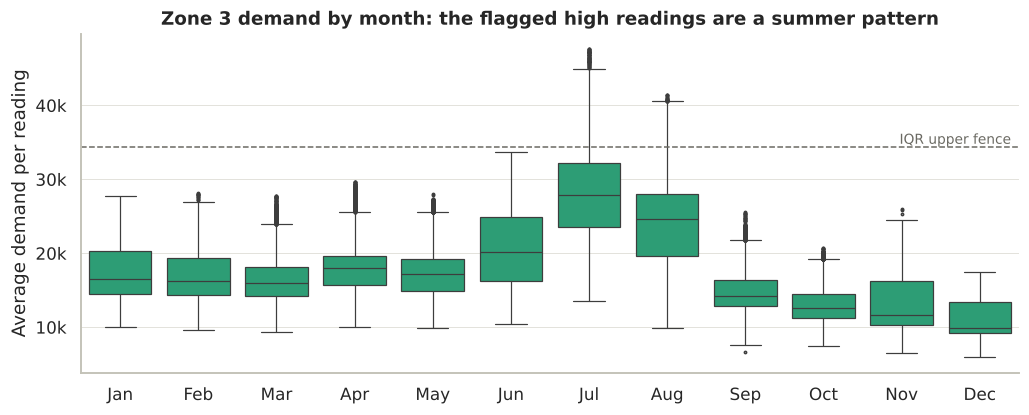

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="MonthName", y="PowerConsumption_Zone3", color="#1baf7a",
            fliersize=1.5, linewidth=0.8, ax=ax)
ax.axhline(z3_upper, color="#6b6a63", ls="--", lw=1)
ax.text(11.4, z3_upper, " IQR upper fence", va="bottom", ha="right", fontsize=9, color="#6b6a63")
ax.yaxis.set_major_formatter(kw_fmt)
ax.set(title="Zone 3 demand by month: the flagged high readings are a summer pattern", xlabel="", ylabel="Average demand per reading")
plt.show()

All flagged Zone 3 readings fall in July and August, and almost all of them happen between 19:00 and 23:00. They follow the daily curve smoothly instead of appearing as isolated spikes, so they reflect genuine summer evening demand rather than recording errors. I kept every reading. Removing them would erase the most important seasonal behaviour in Zone 3.

The small number of Temperature and Humidity outliers are hot summer afternoons and very dry or very humid spells, which are all physically plausible. No readings are negative or impossible.

### 2.4 Wind speed check

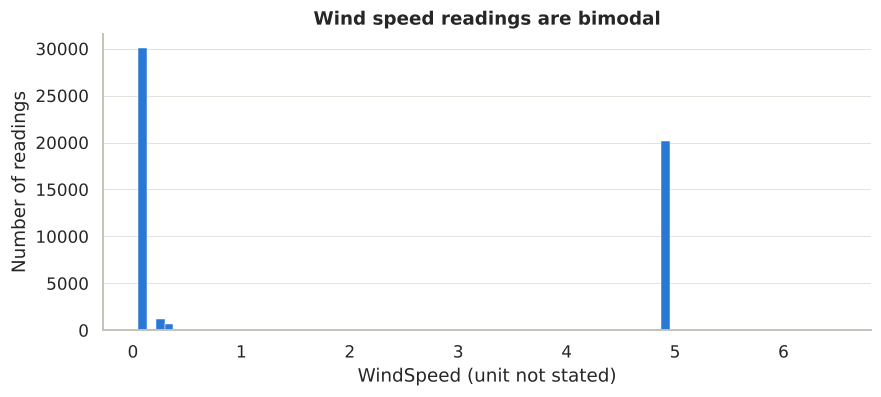

Readings below 1: 61.2% | readings above 1: 38.8%
{'Jan': 0.13, 'Feb': 0.21, 'Mar': 0.19, 'Apr': 0.03, 'May': 0.46, 'Jun': 0.31, 'Jul': 0.94, 'Aug': 0.92, 'Sep': 0.57, 'Oct': 0.56, 'Nov': 0.25, 'Dec': 0.04}


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df["WindSpeed"], bins=80, color="#2a78d6", edgecolor="white", linewidth=0.3)
ax.set(title="Wind speed readings are bimodal", xlabel="WindSpeed (unit not stated)", ylabel="Number of readings")
plt.show()

low = (df["WindSpeed"] < 1).mean()
print(f"Readings below 1: {low:.1%} | readings above 1: {1 - low:.1%}")
print(df.assign(High=df["WindSpeed"] > 1).groupby("MonthName", observed=True)["High"].mean().round(2).to_dict())

Wind speed is not a smooth continuous measure here. About 61% of readings sit around 0.08 and the rest sit around 4.9, with almost nothing in between. That points to a sensor that switches between two states, or values recorded in a different way at different times. I kept the field but I treat any wind speed result as weak evidence.

### 2.5 Analysis-ready dataset

The cleaned 10-minute data is in `df`. I also create hourly and daily averages, which are easier to read for trends and for the environmental analysis.

In [16]:
df_long = (df.reset_index()
             .melt(id_vars=["Datetime", "Month", "MonthName", "Hour", "DayOfWeek", "Date", "IsWeekend"] + ENV,
                   value_vars=ZONES, var_name="Zone", value_name="Demand"))
df_long["Zone"] = df_long["Zone"].map(ZONE_LABELS)

hourly = df[ZONES + ENV].resample("h").mean()
daily = df[ZONES + ENV].resample("D").mean()
print("10-minute:", df.shape, "| hourly:", hourly.shape, "| daily:", daily.shape, "| long format:", df_long.shape)

10-minute: (52416, 16) | hourly: (8736, 6) | daily: (364, 6) | long format: (157248, 12)


## 3. Electricity Consumption Analysis

### 3.1 Overall consumption by zone

In [17]:
summary = df[ZONES].agg(["mean", "median", "std", "min", "max"]).T
summary["cv_%"] = summary["std"] / summary["mean"] * 100
summary["share_of_avg_demand_%"] = summary["mean"] / summary["mean"].sum() * 100
summary["peak_to_min_ratio"] = summary["max"] / summary["min"]
summary.index = summary.index.map(ZONE_LABELS)
summary

,mean,median,std,min,max,cv_%,share_of_avg_demand_%,peak_to_min_ratio
Zone 1,"32,344.97","32,265.92","7,130.56","13,895.70","52,204.40",22.05,45.41,3.76
Zone 2,"21,042.51","20,823.17","5,201.47","8,560.08","37,408.86",24.72,29.54,4.37
Zone 3,"17,835.41","16,415.12","6,622.17","5,935.17","47,598.33",37.13,25.04,8.02


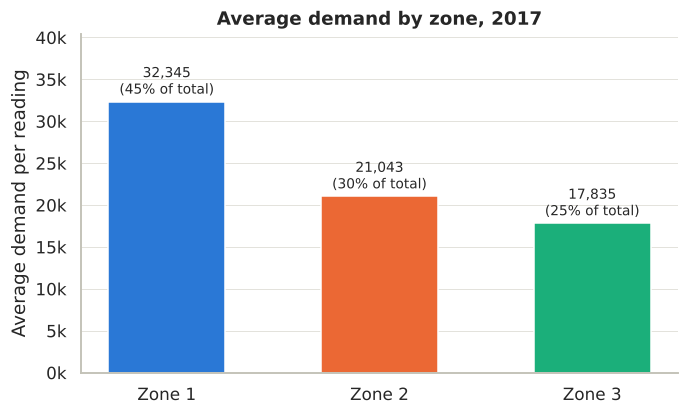

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
means = summary["mean"]
bars = ax.bar(means.index, means.values, color=[ZONE_COLORS[z] for z in means.index], width=0.55)
for b, (z, v) in zip(bars, means.items()):
    ax.text(b.get_x() + b.get_width() / 2, v + 400, f"{v:,.0f}\n({summary.loc[z, 'share_of_avg_demand_%']:.0f}% of total)",
            ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(kw_fmt)
ax.set_ylim(0, means.max() * 1.25)
ax.set(title="Average demand by zone, 2017", ylabel="Average demand per reading")
plt.savefig(IMG_DIR / "02_zone_average.png")
plt.show()

Zone 1 is the largest zone by a clear margin, accounting for about 45% of the combined average demand. Zone 2 is second (about 30%) and Zone 3 is the smallest on average (about 25%). Zone 3 is, however, the most variable zone, with a coefficient of variation of 37% compared with 22% for Zone 1.

### 3.2 Consumption over time

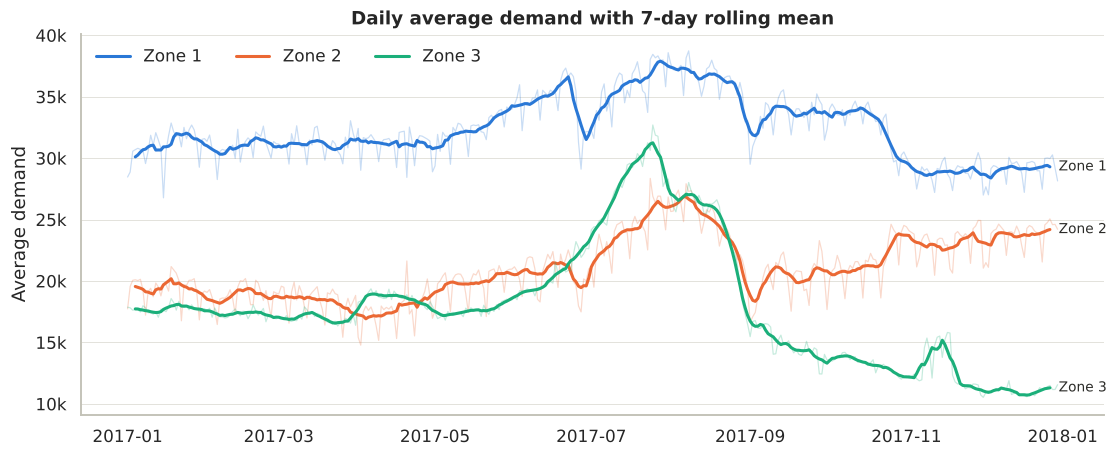

In [19]:
daily_avg = daily[ZONES].rename(columns=ZONE_LABELS)
rolling = daily_avg.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
for z in daily_avg.columns:
    ax.plot(daily_avg.index, daily_avg[z], color=ZONE_COLORS[z], alpha=0.25, lw=0.8)
    ax.plot(rolling.index, rolling[z], color=ZONE_COLORS[z], lw=2, label=z)
    ax.text(rolling.index[-4], rolling[z].dropna().iloc[-1], f"  {z}", color="#2b2b28", va="center", fontsize=9)
ax.yaxis.set_major_formatter(kw_fmt)
ax.set(title="Daily average demand with 7-day rolling mean", ylabel="Average demand")
ax.legend(loc="upper left", ncol=3)
plt.savefig(IMG_DIR / "01_daily_trend.png")
plt.show()

In [20]:
peaks = pd.DataFrame({
    "highest_reading": df[ZONES].max(), "highest_reading_time": df[ZONES].idxmax(),
    "lowest_reading": df[ZONES].min(), "lowest_reading_time": df[ZONES].idxmin(),
    "highest_day": daily[ZONES].idxmax().dt.date, "lowest_day": daily[ZONES].idxmin().dt.date,
})
peaks.index = peaks.index.map(ZONE_LABELS)
peaks

,highest_reading,highest_reading_time,lowest_reading,lowest_reading_time,highest_day,lowest_day
Zone 1,"52,204.40",2017-08-07 20:20:00,"13,895.70",2017-01-15 07:30:00,2017-08-08,2017-01-15
Zone 2,"37,408.86",2017-07-24 19:40:00,"8,560.08",2017-04-02 06:10:00,2017-07-24,2017-04-02
Zone 3,"47,598.33",2017-07-24 20:10:00,"5,935.17",2017-12-11 07:00:00,2017-07-25,2017-12-01


Zones 1 and 2 move fairly steadily through the year, rising into the summer. Zone 3 behaves very differently: its demand climbs sharply in June, peaks in July and then drops to the lowest levels of the year from September onwards. The highest individual readings for all three zones occurred on summer evenings (late July and early August, around 19:40 to 20:20). The lowest readings all occurred in the early morning around 06:00 to 07:30.

### 3.3 Hourly pattern

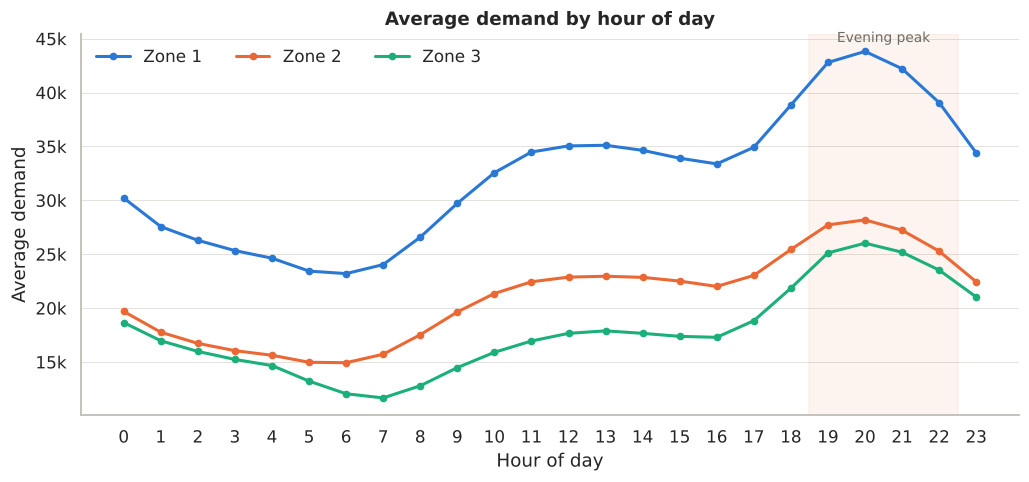

,peak_hour,peak_avg,lowest_hour,lowest_avg,peak_vs_lowest_%
Zone 1,20,"43,822.59",6,"23,203.60",88.86
Zone 2,20,"28,186.91",6,"14,934.70",88.73
Zone 3,20,"26,027.61",7,"11,667.86",123.07


In [21]:
hourly_profile = df.groupby("Hour")[ZONES].mean().rename(columns=ZONE_LABELS)

fig, ax = plt.subplots(figsize=(11, 4.5))
for z in hourly_profile.columns:
    ax.plot(hourly_profile.index, hourly_profile[z], color=ZONE_COLORS[z], lw=2, marker="o", ms=4, label=z)
ax.axvspan(18.5, 22.5, color="#eb6834", alpha=0.07)
ax.text(20.5, hourly_profile.values.max() * 1.02, "Evening peak", ha="center", fontsize=9, color="#6b6a63")
ax.set_xticks(range(0, 24))
ax.yaxis.set_major_formatter(kw_fmt)
ax.set(title="Average demand by hour of day", xlabel="Hour of day", ylabel="Average demand")
ax.legend(loc="upper left", ncol=3)
plt.savefig(IMG_DIR / "03_hourly_profile.png")
plt.show()

hour_stats = pd.DataFrame({
    "peak_hour": hourly_profile.idxmax(), "peak_avg": hourly_profile.max(),
    "lowest_hour": hourly_profile.idxmin(), "lowest_avg": hourly_profile.min(),
})
hour_stats["peak_vs_lowest_%"] = (hour_stats["peak_avg"] / hour_stats["lowest_avg"] - 1) * 100
hour_stats

All three zones share the same daily shape. Demand bottoms out between 06:00 and 07:00, climbs through the morning, holds steady over midday and the afternoon, and then rises to a sharp peak at **20:00**. The evening peak is roughly 89% above the early-morning low in Zones 1 and 2, and more than double the low in Zone 3 (about 123% higher). This evening peak is the most consistent pattern in the data and the most important one for capacity planning.

### 3.4 Daily and weekly patterns

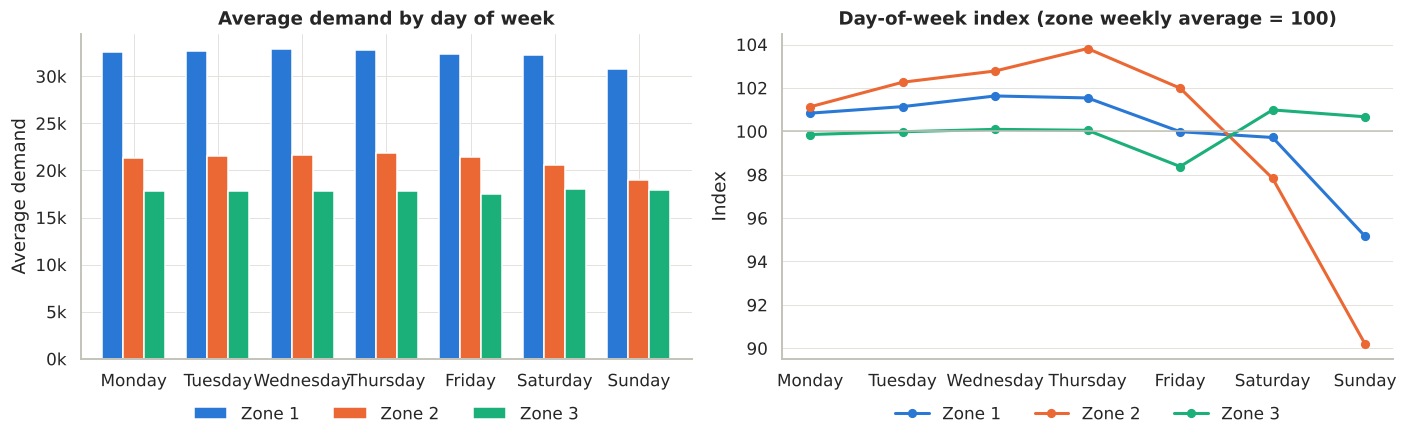

,Zone 1,Zone 2,Zone 3
IsWeekend,,,
Weekday,"32,676.34","21,546.45","17,776.37"
Weekend,"31,516.56","19,782.67","17,983.01"
Weekend vs weekday %,-3.55,-8.19,1.16


In [22]:
dow_profile = df.groupby("DayOfWeek", observed=True)[ZONES].mean().rename(columns=ZONE_LABELS)
dow_index = dow_profile / dow_profile.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
dow_profile.plot(kind="bar", color=[ZONE_COLORS[z] for z in dow_profile.columns], width=0.75, ax=axes[0], edgecolor="white")
axes[0].yaxis.set_major_formatter(kw_fmt)
axes[0].set(title="Average demand by day of week", xlabel="", ylabel="Average demand")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))

for z in dow_index.columns:
    axes[1].plot(dow_index.index.astype(str), dow_index[z], color=ZONE_COLORS[z], lw=2, marker="o", ms=5, label=z)
axes[1].axhline(100, color="#c3c2b7", lw=1)
axes[1].set(title="Day-of-week index (zone weekly average = 100)", xlabel="", ylabel="Index")
axes[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.savefig(IMG_DIR / "04_weekday_profile.png")
plt.show()

weekend = df.groupby("IsWeekend")[ZONES].mean().rename(columns=ZONE_LABELS, index={False: "Weekday", True: "Weekend"})
weekend.loc["Weekend vs weekday %"] = (weekend.loc["Weekend"] / weekend.loc["Weekday"] - 1) * 100
weekend

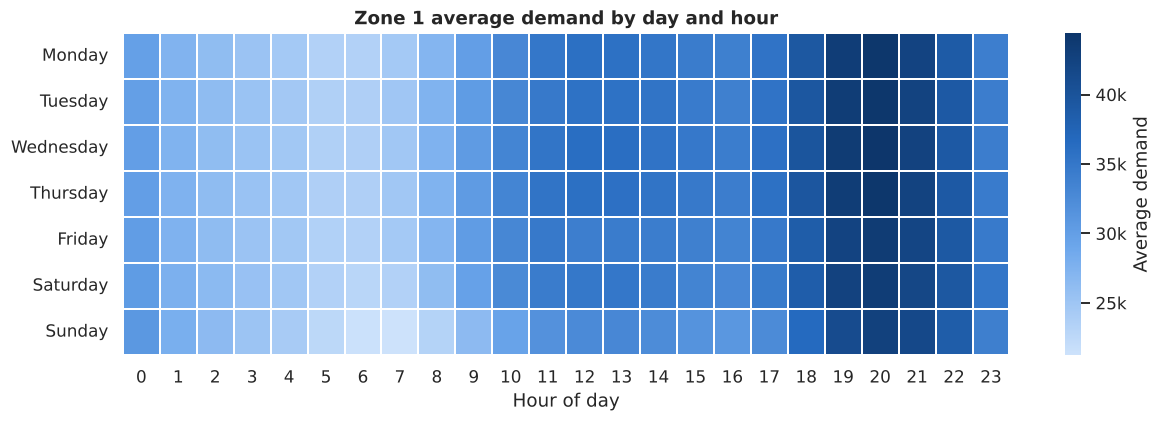

In [23]:
heat = df.groupby(["DayOfWeek", "Hour"], observed=True)["PowerConsumption_Zone1"].mean().unstack()
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat, cmap=SEQUENTIAL, ax=ax, cbar_kws={"label": "Average demand", "format": kw_fmt}, linewidths=0.3, linecolor="white")
ax.set(title="Zone 1 average demand by day and hour", xlabel="Hour of day", ylabel="")
plt.show()

Weekday demand is very stable from Monday to Friday. **Sunday is the lowest day** in Zones 1 and 2 (about 5% and 10% below their weekly averages), and Saturday is also slightly lower in Zone 2. Zone 3 hardly changes across the week, which may mean its customer base is more residential, although the data does not say what type of customers each zone serves. The heatmap shows that the weekend dip in Zone 1 is concentrated in the morning: Sunday mornings start later and lower, while the evening peak is still present every day.

### 3.5 Monthly pattern

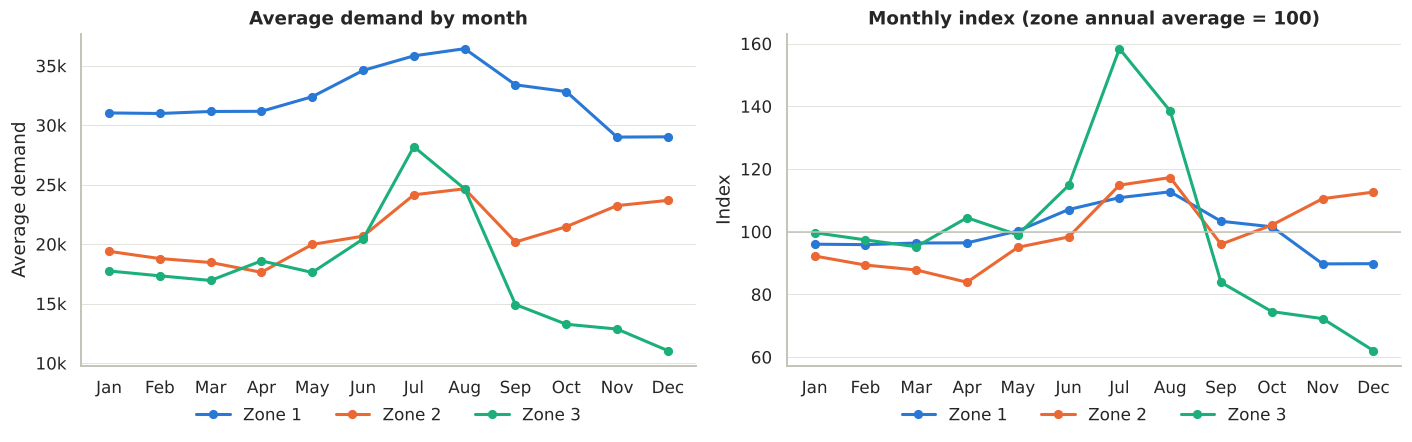

,highest_month,highest_avg,lowest_month,lowest_avg,highest_vs_lowest_%
Zone 1,Aug,"36,435.19",Nov,"29,002.11",25.63
Zone 2,Aug,"24,656.22",Apr,"17,633.97",39.82
Zone 3,Jul,"28,194.11",Dec,"11,044.81",155.27


In [24]:
monthly_profile = df.groupby("MonthName", observed=True)[ZONES].mean().rename(columns=ZONE_LABELS)
monthly_index = monthly_profile / monthly_profile.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for z in monthly_profile.columns:
    axes[0].plot(monthly_profile.index.astype(str), monthly_profile[z], color=ZONE_COLORS[z], lw=2, marker="o", ms=5, label=z)
    axes[1].plot(monthly_index.index.astype(str), monthly_index[z], color=ZONE_COLORS[z], lw=2, marker="o", ms=5, label=z)
axes[0].yaxis.set_major_formatter(kw_fmt)
axes[0].set(title="Average demand by month", ylabel="Average demand")
axes[1].axhline(100, color="#c3c2b7", lw=1)
axes[1].set(title="Monthly index (zone annual average = 100)", ylabel="Index")
for a in axes:
    a.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(IMG_DIR / "05_monthly_profile.png")
plt.show()

month_stats = pd.DataFrame({
    "highest_month": monthly_profile.idxmax(), "highest_avg": monthly_profile.max(),
    "lowest_month": monthly_profile.idxmin(), "lowest_avg": monthly_profile.min(),
})
month_stats["highest_vs_lowest_%"] = (month_stats["highest_avg"] / month_stats["lowest_avg"] - 1) * 100
month_stats

Summer is the busiest period for every zone, but the zones differ a lot in how strongly they react:

- **Zone 1** peaks in August and is lowest in November and December. The gap between its best and worst month is about 26%.
- **Zone 2** peaks in August, falls to its lowest point in April, and then **rises again from October to December**, ending the year well above its spring level. That late-year rise does not appear in the other zones.
- **Zone 3** has by far the strongest seasonality. July demand is about 2.5 times December demand, and from September onwards Zone 3 drops well below its annual average.

Because the data covers only one year, I cannot confirm whether these monthly patterns repeat every year or whether part of the movement (for example Zone 2's late-year rise) reflects a one-off change in that network.

### 3.6 How similar are the three zones?

In [25]:
zone_corr = hourly[ZONES].rename(columns=ZONE_LABELS).corr()
zone_corr_daily = daily[ZONES].rename(columns=ZONE_LABELS).corr()
print("Correlation between zones (hourly averages):")
display(zone_corr.round(2))
print("Correlation between zones (daily averages):")
display(zone_corr_daily.round(2))

Correlation between zones (hourly averages):


,Zone 1,Zone 2,Zone 3
Zone 1,1.00,0.83,0.75
Zone 2,0.83,1.00,0.57
Zone 3,0.75,0.57,1.00


Correlation between zones (daily averages):


,Zone 1,Zone 2,Zone 3
Zone 1,1.00,0.39,0.71
Zone 2,0.39,1.00,0.23
Zone 3,0.71,0.23,1.00


At the hourly level the zones are strongly correlated (0.57 to 0.83) because they share the same daily cycle. At the daily level the relationship between Zone 2 and the other two zones becomes much weaker, because Zone 2's seasonal shape is different. This tells me the zones cannot be forecast or planned as one combined load; each needs its own profile.

## 4. Environmental Relationship Analysis

I look at the relationships in three ways, because each one controls for a different source of confusion:

1. **10-minute correlations**, using all readings.
2. **Daily-average correlations**, which remove the daily cycle and show whether warmer or more humid days have higher demand.
3. **Within-hour correlations**, which compare readings taken at the same hour of the day. Temperature and demand both follow a daily cycle (temperature peaks in the afternoon, demand peaks in the evening), so comparing within the same hour reduces the effect of time of day.

I report both Pearson (linear relationship) and Spearman (monotonic relationship based on ranks). Spearman is the more reliable measure here because the wind speed field is bimodal and several variables are skewed.

In [26]:
def corr_table(data, method):
    return data[ENV + ZONES].corr(method=method).loc[ENV, ZONES].rename(columns=ZONE_LABELS)

pearson_10 = corr_table(df, "pearson")
spearman_10 = corr_table(df, "spearman")
spearman_daily = corr_table(daily, "spearman")
pearson_daily = corr_table(daily, "pearson")

within_hour = (df.groupby("Hour")[ENV + ZONES]
                 .apply(lambda g: g.corr(method="spearman").loc[ENV, ZONES].stack())
                 .median()
                 .unstack()
                 .rename(columns=ZONE_LABELS))

env_summary = pd.concat({
    "Pearson (10-min)": pearson_10, "Spearman (10-min)": spearman_10,
    "Pearson (daily)": pearson_daily, "Spearman (daily)": spearman_daily,
    "Spearman (within hour, median)": within_hour,
})
env_summary.round(2)

Zone 1  Zone 2  Zone 3
Pearson (10-min)               Temperature    0.44    0.38    0.49
                               Humidity      -0.29   -0.29   -0.23
                               WindSpeed      0.17    0.15    0.28
Spearman (10-min)              Temperature    0.43    0.38    0.44
                               Humidity      -0.30   -0.31   -0.21
                               WindSpeed      0.11    0.09    0.08
Pearson (daily)                Temperature    0.73    0.42    0.61
                               Humidity      -0.21   -0.21   -0.26
                               WindSpeed      0.47    0.30    0.41
Spearman (daily)               Temperature    0.72    0.39    0.47
                               Humidity      -0.11   -0.13   -0.11
                               WindSpeed      0.38    0.20    0.14
Spearman (within hour, median) Temperature    0.56    0.34    0.47
                               Humidity      -0.06   -0.10   -0.08
                               WindSpeed      0.25    0.15    0.09

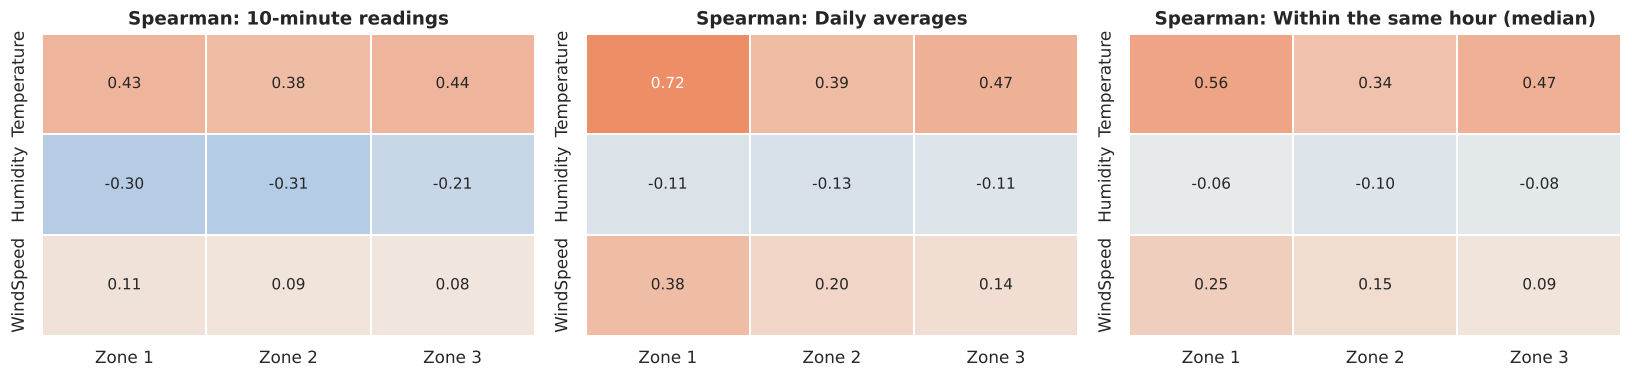

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (title, tbl) in zip(axes, [("10-minute readings", spearman_10), ("Daily averages", spearman_daily), ("Within the same hour (median)", within_hour)]):
    sns.heatmap(tbl, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, cbar=False, ax=ax,
                linewidths=1, linecolor="white", annot_kws={"fontsize": 10})
    ax.set(title=f"Spearman: {title}", xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(IMG_DIR / "06_environment_correlation.png")
plt.show()

In [28]:
from scipy import stats

rows = []
for e in ENV:
    for z in ZONES:
        rho, p = stats.spearmanr(daily[e], daily[z], nan_policy="omit")
        rows.append({"variable": e, "zone": ZONE_LABELS[z], "spearman_rho_daily": rho, "p_value": p})
pd.DataFrame(rows).pivot(index="variable", columns="zone", values="spearman_rho_daily").round(2)

zone,Zone 1,Zone 2,Zone 3
variable,,,
Humidity,-0.11,-0.13,-0.11
Temperature,0.72,0.39,0.47
WindSpeed,0.38,0.20,0.14


### 4.1 Temperature

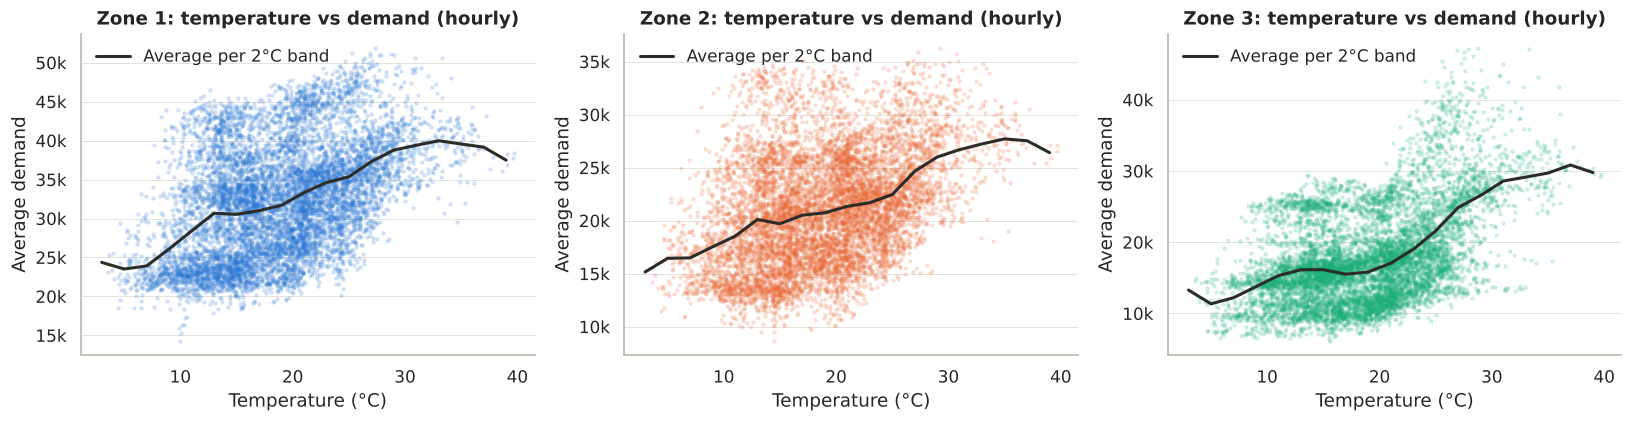

In [29]:
sample = hourly.dropna().rename(columns=ZONE_LABELS)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, z in zip(axes, ["Zone 1", "Zone 2", "Zone 3"]):
    ax.scatter(sample["Temperature"], sample[z], s=4, alpha=0.15, color=ZONE_COLORS[z])
    bins = pd.cut(sample["Temperature"], np.arange(0, 42, 2))
    trend = sample.groupby(bins, observed=True)[[z]].mean()
    centres = [b.mid for b in trend.index]
    ax.plot(centres, trend[z], color="#2b2b28", lw=2, label="Average per 2°C band")
    ax.yaxis.set_major_formatter(kw_fmt)
    ax.set(title=f"{z}: temperature vs demand (hourly)", xlabel="Temperature (°C)", ylabel="Average demand")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [30]:
temp_bands = df.assign(TempBand=pd.cut(df["Temperature"], [0, 10, 15, 20, 25, 30, 45],
                                      labels=["<10°C", "10-15°C", "15-20°C", "20-25°C", "25-30°C", ">30°C"]))
band_table = temp_bands.groupby("TempBand", observed=True)[ZONES].mean().rename(columns=ZONE_LABELS)
band_table["readings"] = temp_bands["TempBand"].value_counts().sort_index()
band_table

,Zone 1,Zone 2,Zone 3,readings
TempBand,,,,
<10°C,"25,340.18","17,171.09","13,174.97",2890
10-15°C,"29,906.67","19,496.48","15,899.82",12071
15-20°C,"31,190.44","20,427.71","15,764.11",14938
20-25°C,"34,005.29","21,572.50","18,369.32",14486
25-30°C,"37,287.10","24,486.07","24,523.26",6594
>30°C,"39,500.95","27,062.10","28,928.12",1437


Temperature has the strongest and most consistent relationship with demand. It is **moderate and positive** across all zones (Spearman about 0.4 on 10-minute data) and becomes **strong for Zone 1 on daily averages** (about 0.72). The relationship still holds when I compare readings from the same hour, so it is not only a by-product of the daily cycle. Average demand rises step by step across the temperature bands: Zone 1 averages about 25,000 below 10°C and about 39,500 above 30°C, and Zone 3 more than doubles over the same range.

The relationship looks like cooling demand: there is no clear rise in demand on the coldest days, which suggests heating load is small in this climate compared with summer cooling load.

### 4.2 Humidity and wind speed

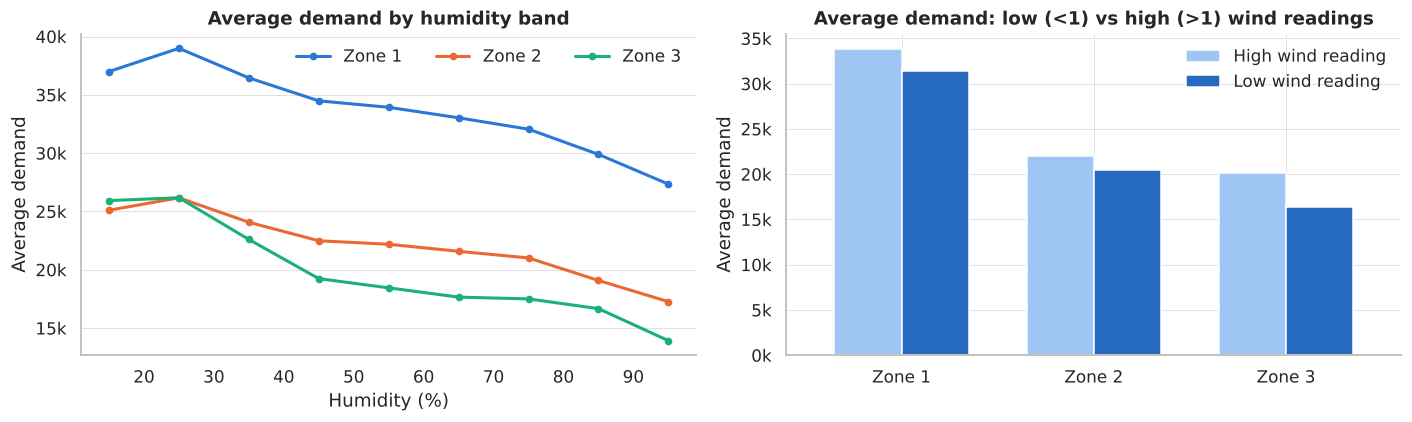

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for z in ["Zone 1", "Zone 2", "Zone 3"]:
    hb = sample.groupby(pd.cut(sample["Humidity"], np.arange(10, 101, 10)), observed=True)[z].mean()
    axes[0].plot([b.mid for b in hb.index], hb.values, color=ZONE_COLORS[z], lw=2, marker="o", ms=4, label=z)
wind = sample.groupby(np.where(sample["WindSpeed"] > 1, "High wind reading", "Low wind reading"))[["Zone 1", "Zone 2", "Zone 3"]].mean()
wind.T.plot(kind="bar", ax=axes[1], color=["#9ec5f4", "#256abf"], width=0.7, edgecolor="white")
axes[1].tick_params(axis="x", rotation=0)
axes[0].yaxis.set_major_formatter(kw_fmt)
axes[0].set(title="Average demand by humidity band", xlabel="Humidity (%)", ylabel="Average demand")
axes[0].legend(ncol=3)
axes[1].yaxis.set_major_formatter(kw_fmt)
axes[1].set(title="Average demand: low (<1) vs high (>1) wind readings", ylabel="Average demand")
plt.tight_layout()
plt.show()

**Humidity** has a weak negative relationship with demand (about -0.2 to -0.3 on 10-minute data). Within the same hour it almost disappears (about -0.1). Humidity is highest at night and in the early morning, which is when demand is lowest, so most of the overall correlation is explained by time of day rather than humidity itself.

**Wind speed** has a weak positive relationship that is stronger on daily averages for Zone 1 (about 0.4). Because the field is bimodal and the "high" readings are more common in the warmer months, I believe most of this relationship comes from seasonality, not from wind affecting demand. I would not use wind speed for planning without first confirming how it is measured.

### 4.3 Correlation is not causation

These results show association, not cause and effect. Temperature, humidity, wind and demand all change with the time of day and the season, so part of every correlation comes from those shared cycles. Other drivers that are not in the data (daylight hours, holidays, school terms, tourism, Ramadan, which ran from late May to late June 2017, and the type of customers in each zone) could explain part of the patterns. Consecutive readings are also not independent, so p-values from 10-minute data overstate how certain the results are. That is why I focus on the size and direction of the correlations and on how consistent they are across the three views.

## 5. Interactive Visualisation (Plotly)

The Matplotlib and Seaborn charts above are saved in the `images/` folder. The interactive Plotly charts below let a reader zoom into any period, hover for exact values and switch zones on or off. All of them are also exported to `reports/interactive_charts.html`, which opens in any browser without Python.

In [32]:
plotly_layout = dict(template="plotly_white", font=dict(family="Arial", size=12),
                     legend=dict(orientation="h", y=1.08, x=0), margin=dict(l=60, r=30, t=80, b=50),
                     hovermode="x unified")
figs = {}

d = daily[ZONES].rename(columns=ZONE_LABELS).reset_index().melt(id_vars="Datetime", var_name="Zone", value_name="Demand")
fig = px.line(d, x="Datetime", y="Demand", color="Zone", color_discrete_map=ZONE_COLORS,
              title="Daily average demand by zone, 2017 (drag the slider to zoom)")
fig.update_traces(line_width=1.8, hovertemplate="%{y:,.0f}")
fig.update_layout(**plotly_layout, yaxis_title="Average demand", xaxis_title="")
fig.update_xaxes(rangeslider_visible=True)
figs["trend"] = fig
fig.show()

In [33]:
z = summary.reset_index().rename(columns={"index": "Zone"})
fig = px.bar(z, x="Zone", y="mean", color="Zone", color_discrete_map=ZONE_COLORS, text="mean",
             title="Average demand by zone",
             hover_data={"median": ":,.0f", "std": ":,.0f", "cv_%": ":.1f", "share_of_avg_demand_%": ":.1f"})
fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside", width=0.55)
fig.update_layout(**{**plotly_layout, "hovermode": "closest"}, yaxis_title="Average demand", xaxis_title="", showlegend=False)
figs["zone_average"] = fig
fig.show()

In [34]:
h = hourly_profile.reset_index().melt(id_vars="Hour", var_name="Zone", value_name="Demand")
fig = px.line(h, x="Hour", y="Demand", color="Zone", color_discrete_map=ZONE_COLORS, markers=True,
              title="Average demand by hour of day")
fig.update_traces(hovertemplate="%{y:,.0f}")
fig.update_layout(**plotly_layout, yaxis_title="Average demand", xaxis=dict(dtick=1, title="Hour of day"))
figs["hourly"] = fig
fig.show()

In [35]:
heat_all = (df_long.groupby(["Zone", "DayOfWeek", "Hour"], observed=True)["Demand"].mean().reset_index())
fig = go.Figure()
for i, zname in enumerate(["Zone 1", "Zone 2", "Zone 3"]):
    m = heat_all[heat_all["Zone"] == zname].pivot(index="DayOfWeek", columns="Hour", values="Demand")
    fig.add_trace(go.Heatmap(z=m.values, x=m.columns, y=m.index.astype(str), visible=(i == 0),
                             colorscale=[[0, "#cde2fb"], [0.35, "#6da7ec"], [0.7, "#256abf"], [1, "#0d366b"]],
                             hovertemplate="%{y}, %{x}:00<br>Average demand: %{z:,.0f}<extra></extra>",
                             colorbar=dict(title="Demand")))
fig.update_layout(
    **{**plotly_layout, "hovermode": "closest"}, title="Average demand by day and hour (use the buttons to switch zone)",
    xaxis=dict(dtick=1, title="Hour of day"), yaxis=dict(autorange="reversed"),
    updatemenus=[dict(type="buttons", direction="right", x=1, xanchor="right", y=1.15,
                      buttons=[dict(label=zn, method="update", args=[{"visible": [j == i for j in range(3)]}])
                               for i, zn in enumerate(["Zone 1", "Zone 2", "Zone 3"])])])
figs["day_hour_heatmap"] = fig
fig.show()

In [36]:
mth = monthly_profile.reset_index().melt(id_vars="MonthName", var_name="Zone", value_name="Demand")
mth["MonthName"] = mth["MonthName"].astype(str)
fig = px.bar(mth, x="MonthName", y="Demand", color="Zone", barmode="group", color_discrete_map=ZONE_COLORS,
             title="Average demand by month", category_orders={"MonthName": MONTH_ORDER})
fig.update_traces(hovertemplate="%{y:,.0f}")
fig.update_layout(**plotly_layout, yaxis_title="Average demand", xaxis_title="")
figs["monthly"] = fig
fig.show()

In [37]:
dw = dow_profile.reset_index().melt(id_vars="DayOfWeek", var_name="Zone", value_name="Demand")
dw["DayOfWeek"] = dw["DayOfWeek"].astype(str)
fig = px.bar(dw, x="DayOfWeek", y="Demand", color="Zone", barmode="group", color_discrete_map=ZONE_COLORS,
             title="Average demand by day of week", category_orders={"DayOfWeek": DAY_ORDER})
fig.update_traces(hovertemplate="%{y:,.0f}")
fig.update_layout(**plotly_layout, yaxis_title="Average demand", xaxis_title="")
figs["weekday"] = fig
fig.show()

In [38]:
sc = hourly.dropna().rename(columns=ZONE_LABELS).reset_index()
sc = sc.melt(id_vars=["Datetime"] + ENV, value_vars=["Zone 1", "Zone 2", "Zone 3"], var_name="Zone", value_name="Demand")
fig = px.scatter(sc, x="Temperature", y="Demand", color="Zone", color_discrete_map=ZONE_COLORS, opacity=0.25,
                 hover_data={"Datetime": True, "Humidity": ":.1f", "Temperature": ":.1f", "Demand": ":,.0f"},
                 title="Hourly demand vs temperature (click a zone in the legend to hide it)")
fig.update_traces(marker_size=4)
fig.update_layout(**{**plotly_layout, "hovermode": "closest"}, xaxis_title="Temperature (°C)", yaxis_title="Average demand")
figs["temperature"] = fig
fig.show()

In [39]:
fig = px.imshow(spearman_daily.round(2), text_auto=True, zmin=-1, zmax=1,
                color_continuous_scale=[[0, "#2a78d6"], [0.5, "#f2f1ec"], [1, "#eb6834"]],
                title="Spearman correlation: environment vs demand (daily averages)", aspect="auto")
fig.update_layout(**{**plotly_layout, "hovermode": "closest"})
figs["env_corr"] = fig
fig.show()

In [40]:
fig = px.box(df_long.sample(20000, random_state=42).sort_values("Zone"), x="Zone", y="Demand", color="Zone",
             color_discrete_map=ZONE_COLORS, title="Distribution of 10-minute demand by zone (random sample of 20,000 readings)")
fig.update_layout(**{**plotly_layout, "hovermode": "closest"}, showlegend=False, yaxis_title="Demand", xaxis_title="")
figs["zone_distribution"] = fig
fig.show()

In [41]:
parts = [f.to_html(full_html=False, include_plotlyjs=("cdn" if i == 0 else False)) for i, f in enumerate(figs.values())]
page = f'''<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Morocco Electricity Consumption 2017 - Interactive Charts</title>
<style>body{{font-family:Arial,sans-serif;max-width:1100px;margin:30px auto;padding:0 20px;color:#2b2b28}}
h1{{font-size:24px;margin-bottom:4px}} p{{color:#5a5953;margin-top:0}} .chart{{margin:28px 0;border-top:1px solid #e1e0d9;padding-top:12px}}</style>
</head><body>
<h1>Morocco Electricity Consumption, 2017</h1>
<p>Interactive charts from my Week 5 analysis of 10-minute demand readings for three zones in Tetouan. Hover for values, drag to zoom, click legend items to show or hide a zone.</p>
{''.join(f'<div class="chart">{p}</div>' for p in parts)}
</body></html>'''
(REPORT_DIR / "interactive_charts.html").write_text(page, encoding="utf-8")
print("Saved:", REPORT_DIR / "interactive_charts.html")

Saved: /home/claude/repo/analystlab-morocco-electricity-consumption/reports/interactive_charts.html


## 6. Business Insights and Recommendations

In [42]:
key_numbers = pd.DataFrame({
    "Average demand": summary["mean"],
    "Share of combined demand %": summary["share_of_avg_demand_%"],
    "Variability (CV %)": summary["cv_%"],
    "Peak hour": hour_stats["peak_hour"],
    "Lowest hour": hour_stats["lowest_hour"],
    "Evening peak vs early-morning low %": hour_stats["peak_vs_lowest_%"],
    "Highest month": month_stats["highest_month"],
    "Lowest month": month_stats["lowest_month"],
    "Best vs worst month %": month_stats["highest_vs_lowest_%"],
    "Sunday vs weekly average %": dow_index.loc["Sunday"] - 100,
    "Temperature rho (daily)": spearman_daily.loc["Temperature"],
}).T
key_numbers

,Zone 1,Zone 2,Zone 3
Average demand,"32,344.97","21,042.51","17,835.41"
Share of combined demand %,45.41,29.54,25.04
Variability (CV %),22.05,24.72,37.13
Peak hour,20,20,20
Lowest hour,6,6,7
Evening peak vs early-morning low %,88.86,88.73,123.07
Highest month,Aug,Aug,Jul
Lowest month,Nov,Apr,Dec
Best vs worst month %,25.63,39.82,155.27
Sunday vs weekly average %,-4.84,-9.80,0.67


### Key findings

1. **Zone 1 carries the largest load.** It averages about 32,300 per reading, roughly 45% of combined demand, followed by Zone 2 (about 21,000, 30%) and Zone 3 (about 17,800, 25%). Zone 3 has the lowest average but the highest variability.
2. **Every zone peaks at 20:00 and bottoms out between 06:00 and 07:00.** The evening peak is about 89% above the early-morning low in Zones 1 and 2, and about 123% above it in Zone 3. The 19:00 to 22:00 window is the critical period for the network.
3. **Summer is the high-demand season, especially for Zone 3.** All zones peak in July or August. Zone 3's July average is about 2.5 times its December average, and all of its unusually high readings fall in July and August.
4. **Zone 2 has a distinct seasonal shape.** It is lowest in April and rises again from October to December, while Zones 1 and 3 are falling over the same months.
5. **Weekly patterns are mild but consistent.** Demand is flat from Monday to Friday. Sunday is the lowest day in Zone 1 (about 5% below its weekly average) and Zone 2 (about 10% below), while Zone 3 barely changes during the week.
6. **Temperature is the environmental factor most associated with demand.** The association is moderate on 10-minute data, strong for Zone 1 on daily averages (Spearman about 0.72) and holds within the same hour of day. Demand rises steadily from below 10°C to above 30°C, which is consistent with cooling demand. Humidity and wind speed show only weak associations that are largely explained by time of day and season.

### What this means for an energy management organisation

- Capacity planning should be built around the **summer evening peak**, not the annual average. The highest readings of the year all occurred between 19:40 and 20:20 in late July and early August.
- The three zones need **separate plans**. Zone 1 needs the most capacity all year round, Zone 3 needs extra capacity for a short summer window, and Zone 2 needs attention at the end of the year as well as in summer.
- Low-demand periods (early mornings, Sundays, and the autumn months for Zone 3) are the natural windows for **planned maintenance** with the least disruption to customers.
- Because temperature moves with demand, **weather forecasts are a useful early signal** for expected load, particularly for Zone 1 and Zone 3.

### Recommendations

1. **Plan peak capacity and reserves around 19:00 to 22:00 in June to August.** Use the summer evening profile of each zone, especially Zone 3, which swings the most, to set reserve margins and to schedule supply or generation ahead of hot evenings.
2. **Introduce demand-shifting measures for the evening peak.** Time-of-use pricing, customer awareness messages on hot days and incentives to move flexible use (water heating, appliances) to the midday or late-night period would flatten the 20:00 peak. Zones 1 and 3 have the most to gain.
3. **Schedule maintenance during low-demand windows.** Prioritise 03:00 to 07:00, Sundays for Zones 1 and 2, and September to December for Zone 3, while avoiding the end of the year for Zone 2.
4. **Build a temperature-aware short-term forecast for each zone.** Combine the hourly and weekly profiles from this analysis with temperature forecasts to predict next-day demand, and track Zone 2 separately because its seasonal pattern differs from the others.
5. **Improve the data before relying on it for long-term decisions.** Confirm the consumption unit and the meaning of the diffuse flow fields, check the wind speed sensor, and collect several more years of data so that seasonal patterns and the Zone 2 year-end rise can be confirmed.

### Limitations

- One year of data cannot separate repeating seasonal patterns from one-off events.
- Units for consumption, wind speed and the diffuse flow fields are not documented, so I compared averages and avoided totals.
- 31 December 2017 is not in the dataset.
- Correlations describe association only. Shared daily and seasonal cycles and factors outside the dataset (holidays, Ramadan, tourism, customer mix) are possible confounders.